# Perbaikan preprocessing dan validasi

Notebook ini membaca keluaran eksperimen aktual setelah pelatihan ulang. Pada saat eksperimen dijalankan, skor Kaggle belum tersedia. Pembaruan 14 Oktober 2026: skor unggahan kandidat 012 dilaporkan **0,60449**, di bawah submission 010 (**0,60627**). Submission 010 tetap menjadi pilihan final. Output analisis lokal di bawah merupakan hasil eksekusi asli dan tidak diubah oleh pembaruan skor publik ini. Kode lengkap ada di `scripts/leakage_fixed.py` dan `scripts/run_fixed_experiment.py`.

In [1]:
from pathlib import Path
import json
import pandas as pd
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
import sys
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
folder = ROOT / 'reports/fixed_run'
metrics = json.loads((folder / 'metrics.json').read_text())
protocol = json.loads((folder / 'protocol.json').read_text())
selection = json.loads((folder / 'frozen_selection.json').read_text())
print(json.dumps(protocol['rows'], indent=2))

{
  "fit": 426772,
  "calibration": 37342,
  "selection": 37342,
  "audit": 32009
}


## Protokol

Statistik konteks hanya dipelajari dari fit. Neighbor target dan TargetEncoder menggunakan cross-fitting. Kalibrasi, seleksi, dan audit terpisah. ID utuh tidak menjadi fitur; fragmen ID masih menjadi proxy lokasi. Audit ini tidak digunakan untuk pemilihan pada run baru, tetapi bukan holdout yang dapat dijamin belum pernah terekspos selama seluruh riwayat eksperimen.

In [2]:
print(pd.DataFrame(selection['all_candidates']).head(10).to_string(index=False))

                                      weights                                                                                                       offsets   cal_f1  selection_f1
         {'lgb47': 0.25, 'cat_numeric': 0.75}               [-0.13400000000000004, 0.196, 0.14600000000000002, -0.003999999999999988, -0.20400000000000001] 0.602895      0.597649
{'lgb31_weighted': 0.25, 'cat_numeric': 0.75}                                [-0.12000000000000001, 0.26000000000000006, 0.16, -0.04000000000000001, -0.26] 0.603307      0.597579
         {'lgb95': 0.25, 'cat_numeric': 0.75}  [-0.13599999999999998, 0.21400000000000002, 0.19400000000000003, 0.013999999999999995, -0.28600000000000003] 0.603154      0.597495
         {'lgb95': 0.25, 'cat_numeric': 0.75} [-0.06799999999999999, 0.10700000000000001, 0.09700000000000002, 0.0069999999999999975, -0.14300000000000002] 0.600500      0.597284
                         {'cat_numeric': 1.0}                                                            

In [3]:
print('Audit Macro F1:', metrics['audit_f1'])
print('Baseline audit:', metrics['audit_raw_lgb47_f1'])
print(pd.DataFrame({k:v for k,v in metrics['audit_classification'].items() if isinstance(v, dict)}).T.to_string())
print('Confusion matrix:')
print(pd.DataFrame(metrics['audit_confusion_matrix'], index=range(1,6), columns=range(1,6)).to_string())

Audit Macro F1: 0.6023587483872423
Baseline audit: 0.5901889878443538
              precision    recall  f1-score  support
1              0.705116  0.687009  0.695945   3310.0
2              0.459033  0.499864  0.478579   3665.0
3              0.477441  0.517103  0.496481   5730.0
4              0.567210  0.577053  0.572089   7722.0
5              0.799180  0.740459  0.768700  11582.0
macro avg      0.601596  0.604298  0.602359  32009.0
weighted avg   0.636950  0.627980  0.631796  32009.0
Confusion matrix:
      1     2     3     4     5
1  2274   694   170    96    76
2   515  1832   889   276   153
3   233   888  2963  1206   440
4   103   325  1352  4456  1486
5   100   252   832  1822  8576


## Visualisasi audit lokal

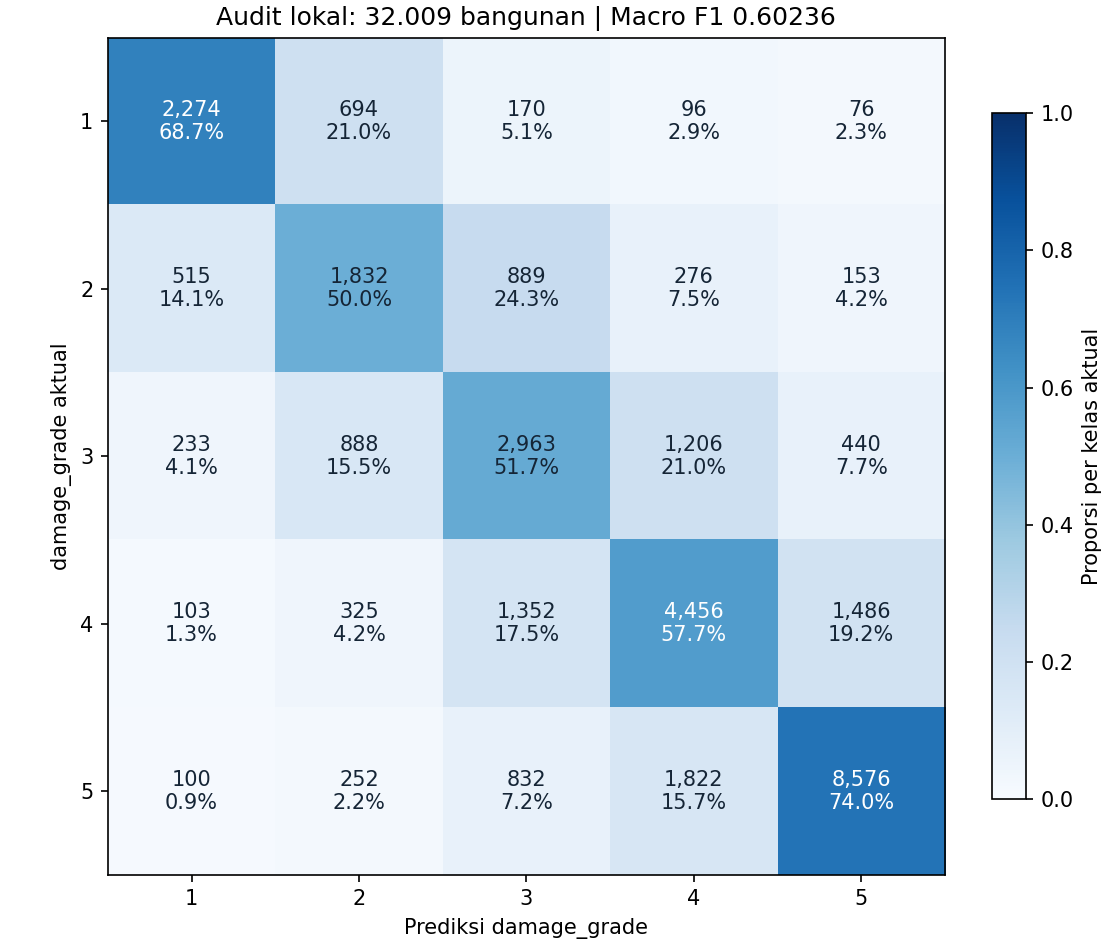

In [4]:
print((folder / 'invariants.json').read_text())
print((folder / 'permutation_control.json').read_text())

{
  "query_label_column_invariance": true,
  "query_batch_invariance": true,
  "no_full_id_feature": true
}
{
  "rows": 8000,
  "fit_rows": 6000,
  "heldout_rows": 2000,
  "labels_permuted_before_split": true,
  "macro_f1": 0.20301857884702637,
  "majority_macro_f1": 0.106529713866471,
  "interpretation": "Low heldout score is consistent with absence of an obvious target shortcut in this small control; it does not certify every code path."
}


In [5]:
submission = pd.read_csv(ROOT / 'submissions/010_Constantine(12).csv', dtype={'building_id':str})
assert list(submission.columns) == ['building_id','damage_grade']
assert len(submission) == 228629 and submission.building_id.is_unique
assert submission.damage_grade.isin([1,2,3,4,5]).all()
import hashlib
assert hashlib.sha256((ROOT / 'submissions/010_Constantine(12).csv').read_bytes()).hexdigest() == metrics['submission_sha256']
print('Checksum CSV cocok dengan eksperimen')
print(submission.head().to_string(index=False))
print(submission.damage_grade.value_counts().sort_index().to_string())

Checksum CSV cocok dengan eksperimen
 building_id  damage_grade
122207000141             2
284909000871             5
241904000231             4
248308000891             2
300405002981             4
damage_grade
1    23149
2    28945
3    44317
4    54875
5    77343


## Pelatihan ulang

Jalankan `python -m scripts.run_fixed_experiment --data data --output artifacts/fixed_run` dari root repository. Pelatihan berat dijalankan melalui CLI, bukan diulang ketika notebook analisis ini dibuka. `scripts/predict_fixed.py` dapat memprediksi dari bundle yang telah disimpan. Rincian interpretasi dan keterbatasan berada di `reports/fixed_run/ANALYSIS.md`.

## Jalankan training dari notebook

Sel berikut sengaja menonaktifkan training secara default karena butuh waktu dan memori. Untuk melatih dari awal, sediakan CSV asli dalam folder `data`, ubah `RUN_TRAINING=True`, lalu jalankan sel. Hasil run baru dipisah dari artefak kandidat 012. Jangan memakai hasil audit berkali-kali untuk menyesuaikan parameter.

In [6]:
import subprocess, sys
RUN_TRAINING = False
if RUN_TRAINING:
    subprocess.run([sys.executable, '-m', 'scripts.run_fixed_experiment', '--data', str(ROOT / 'data'), '--output', str(ROOT / 'artifacts/notebook10_new_run')], cwd=ROOT, check=True)
else:
    print('Training tidak dijalankan ulang; tabel di atas adalah hasil eksperimen tersimpan.')

Training tidak dijalankan ulang; tabel di atas adalah hasil eksperimen tersimpan.


## Pipeline dan ColumnTransformer

`SafeFeatures.fit_transform` membuat fitur target tetangga secara cross-fitting. `make_columns` menyusun imputasi numerik, ordinal encoding, dan TargetEncoder multiclass berlipat. `make_fitted_pipeline` menyatukan preprocessing dan estimator tersimpan untuk prediksi dari fitur mentah. Jangan mengevaluasi training lewat `.transform` karena referensi labelnya mencakup baris train sendiri; gunakan evaluasi terpisah atau cross-fitting.

In [7]:
from scripts.leakage_fixed import SafeFeatures, make_columns, make_fitted_pipeline
print(SafeFeatures.__doc__)
print(make_columns.__doc__)
print(make_fitted_pipeline.__doc__)
print((folder / 'bundle_verification.json').read_text())

Use ID fragments only as spatial proxies; never expose full numeric IDs.

    Neighbor targets for training rows are cross-fitted. Query rows never enter
    fitted reference statistics. ID ordering is a hypothesis, not coordinates.
    
Fit category dictionaries on training only and cross-fit multiclass target encoding.
Assemble the fitted preprocessing and estimator for reproducible raw-data prediction.
{
  "sample_rows": 64,
  "reloaded_pipeline_probabilities_match_cache": true,
  "max_absolute_difference": 2.9636896048401695e-08,
  "reloaded_pipeline_labels_match_csv": true,
  "classes_checked": [
    1,
    2,
    3,
    4,
    5
  ],
  "full_test_replay_rows": 228629,
  "full_test_replay_csv_byte_identical": true,
  "full_test_replay_sha256": "b10072cca29ffbfa36d07228d1000139054cfc17193f2f61aedc7a8d3c73a396"
}


In [8]:
importance = pd.read_csv(folder / 'feature_importance.csv')
print(importance.head(15).to_string(index=False))
print('Importance bersifat deskriptif model, bukan efek kausal atau permutation importance.')

                     feature  normalized_model_importance
        numeric__neighbor_10                     0.061291
        numeric__neighbor_21                     0.038380
        numeric__neighbor_20                     0.037833
        numeric__neighbor_30                     0.035815
        numeric__neighbor_19                     0.034830
         numeric__neighbor_9                     0.027968
        numeric__neighbor_18                     0.027536
         numeric__neighbor_6                     0.026331
         numeric__neighbor_4                     0.026018
        numeric__neighbor_22                     0.023746
         numeric__neighbor_7                     0.021367
numeric__prefix6_log_age_dev                     0.019761
        numeric__neighbor_32                     0.018566
         numeric__neighbor_8                     0.018004
        numeric__neighbor_31                     0.017506
Importance bersifat deskriptif model, bukan efek kausal atau permutation